# Make the dataset for IAA for the first pilot

## Combine 2 datasets

In [1]:

import sqlite3
from pathlib import Path

# ============================================================
# 1. FILE PATHS
# ============================================================

PILOT_DB = Path(
    r"C:\Users\alrazz\Desktop\annotator_pilot_250_for_annotation_V2.db"
)

REFERENCE_DB = Path(
    r"C:\Users\alrazz\Documents\Hybrid SP_ID annotation\Combined db\Combined_single.db"
)

OUTPUT_DB = Path(
    r"C:\Users\alrazz\Desktop\pilot_250_two_annotators_2.db"
)

PILOT_TABLE = "annotator_pilot_250_for_annotation"
REFERENCE_TABLE = "texts"


def main():

    # ========================================================
    # 2. CHECK INPUT FILES
    # ========================================================

    for db_path in (PILOT_DB, REFERENCE_DB):
        if not db_path.exists():
            raise FileNotFoundError(
                f"Database not found: {db_path}"
            )

    if OUTPUT_DB.resolve() in (
        PILOT_DB.resolve(),
        REFERENCE_DB.resolve()
    ):
        raise ValueError(
            "Output database must be different from both input databases."
        )

    # ========================================================
    # 3. CREATE A FRESH OUTPUT DATABASE
    # ========================================================

    # Close the output database in other programs before running.
    # Only the output file is deleted; the original databases are safe.
    if OUTPUT_DB.exists():
        try:
            OUTPUT_DB.unlink()
        except PermissionError:
            raise PermissionError(
                f"Cannot delete {OUTPUT_DB}. "
                "Close it in DB Browser for SQLite or another program, "
                "then run the script again."
            )

    conn = sqlite3.connect(str(OUTPUT_DB.resolve()))

    try:

        # Attach the original databases.
        # All queries below read from these databases only.
        conn.execute(
            "ATTACH DATABASE ? AS ref",
            (str(REFERENCE_DB.resolve()),)
        )

        conn.execute(
            "ATTACH DATABASE ? AS pilot",
            (str(PILOT_DB.resolve()),)
        )


        # ====================================================
        # 3B. CHECK AND FIX PILOT TABLE HEADERS
        # ====================================================

        first_row = conn.execute(
            f'SELECT * FROM pilot."{PILOT_TABLE}" LIMIT 1'
        ).fetchone()

        if first_row is None:
            raise ValueError("The pilot table is empty.")

        # Get the current column names
        current_columns = [
            row[1]
            for row in conn.execute(
                f'PRAGMA pilot.table_info("{PILOT_TABLE}")'
            )
        ]

        # Check whether Turku_NLP appears in the first row
        if "Turku_NLP" in first_row:

            print("First row contains headers. Fixing pilot table...")

            # The first row contains the actual column names
            new_columns = [str(value) for value in first_row]

            # Check that the new column names are unique
            if len(new_columns) != len(set(new_columns)):
                raise ValueError(
                    "Duplicate column names found in the first row."
                )

            # Read all remaining rows, excluding the header row
            remaining_rows = conn.execute(
                f'''
                SELECT *
                FROM pilot."{PILOT_TABLE}"
                LIMIT -1 OFFSET 1
                '''
            ).fetchall()

            # Create a corrected temporary table
            conn.execute(
                'DROP TABLE IF EXISTS main.corrected_pilot'
            )

            column_definitions = ", ".join(
                '"' + col.replace('"', '""') + '" TEXT'
                for col in new_columns
            )

            conn.execute(
                f'''
                CREATE TABLE main.corrected_pilot (
                    {column_definitions}
                )
                '''
            )

            # Insert the remaining data
            placeholders = ", ".join(
                "?" for _ in new_columns
            )

            conn.executemany(
                f'''
                INSERT INTO main.corrected_pilot
                VALUES ({placeholders})
                ''',
                remaining_rows
            )

            print("Pilot headers successfully corrected.")

            # Replace the attached pilot table with the corrected table
            conn.execute(
                f'DROP TABLE pilot."{PILOT_TABLE}"'
            )

            conn.execute(
                f'''
                CREATE TABLE pilot."{PILOT_TABLE}" AS
                SELECT * FROM main.corrected_pilot
                '''
            )

            conn.execute(
                'DROP TABLE main.corrected_pilot'
            )

        else:
            print(
                "Pilot headers are already correct. "
                "No changes needed."
            )

        # ====================================================
        # 4. VERIFY REQUIRED COLUMNS
        # ====================================================

        ref_cols = {
            row[1]
            for row in conn.execute(
                f'PRAGMA ref.table_info("{REFERENCE_TABLE}")'
            )
        }

        pilot_cols = {
            row[1]
            for row in conn.execute(
                f'PRAGMA pilot.table_info("{PILOT_TABLE}")'
            )
        }

        required_ref = {
            "f", "o", "s", "rs", "u", "c", "ts", "de",
            "crawl_id", "lang", "prob", "text", "Turku_NLP",
            "Turku_NLP_sub", "source", "Tags", "xml",
            "cluster_size", "seg_langs", "id", "filter", "pii",
            "doc_scores", "web-register", "html_lang"
        }

        required_pilot = {
            "u", "Turku_NLP", "Turku_NLP_sub", "Tags"
        }

        if not required_ref.issubset(ref_cols):
            raise ValueError(
                "Missing reference columns: "
                f"{required_ref - ref_cols}"
            )

        if not required_pilot.issubset(pilot_cols):
            raise ValueError(
                "Missing pilot columns: "
                f"{required_pilot - pilot_cols}"
            )

        # ====================================================
        # 5. CHECK MATCHING IDS AND DUPLICATES
        # ====================================================

        pilot_count = conn.execute(
            f'SELECT COUNT(*) FROM pilot."{PILOT_TABLE}"'
        ).fetchone()[0]

        pilot_distinct_ids = conn.execute(
            f'''
            SELECT COUNT(DISTINCT u)
            FROM pilot."{PILOT_TABLE}"
            WHERE u IS NOT NULL
            '''
        ).fetchone()[0]

        duplicate_pilot_ids = conn.execute(
            f'''
            SELECT COUNT(*)
            FROM (
                SELECT u
                FROM pilot."{PILOT_TABLE}"
                WHERE u IS NOT NULL
                GROUP BY u
                HAVING COUNT(*) > 1
            )
            '''
        ).fetchone()[0]

        duplicate_reference_ids = conn.execute(
            f'''
            SELECT COUNT(*)
            FROM (
                SELECT u
                FROM ref."{REFERENCE_TABLE}"
                WHERE u IS NOT NULL
                GROUP BY u
                HAVING COUNT(*) > 1
            )
            '''
        ).fetchone()[0]

        matched_ids = conn.execute(
            f'''
            SELECT COUNT(DISTINCT p.u)
            FROM pilot."{PILOT_TABLE}" AS p
            INNER JOIN ref."{REFERENCE_TABLE}" AS r
                ON r.u = p.u
            WHERE p.u IS NOT NULL
            '''
        ).fetchone()[0]

        unmatched_pilot_ids = conn.execute(
            f'''
            SELECT COUNT(DISTINCT p.u)
            FROM pilot."{PILOT_TABLE}" AS p
            WHERE p.u IS NOT NULL
              AND NOT EXISTS (
                  SELECT 1
                  FROM ref."{REFERENCE_TABLE}" AS r
                  WHERE r.u = p.u
              )
            '''
        ).fetchone()[0]

        print("========== MATCHING REPORT ==========")
        print(f"Pilot rows: {pilot_count}")
        print(f"Distinct pilot IDs: {pilot_distinct_ids}")
        print(f"Distinct IDs matched: {matched_ids}")
        print(f"Unmatched pilot IDs: {unmatched_pilot_ids}")
        print(
            f"Pilot IDs occurring multiple times: {duplicate_pilot_ids}"
        )
        print(
            "Reference IDs occurring multiple times: "
            f"{duplicate_reference_ids}"
        )
        print("=====================================")

        # ====================================================
        # 6. CREATE THE FINAL TABLE
        # ====================================================

        conn.execute("""
            CREATE TABLE main.texts (
                f TEXT,
                o INTEGER,
                s INTEGER,
                rs INTEGER,
                u TEXT,
                c TEXT,
                ts TEXT,
                de TEXT,
                crawl_id TEXT,
                lang TEXT,
                prob TEXT,
                text TEXT,
                Main_ann_1 TEXT,
                Sub_ann_1 TEXT,
                source TEXT,
                Tag_1 TEXT,
                xml TEXT,
                cluster_size INTEGER,
                seg_langs TEXT,
                id TEXT,
                filter TEXT,
                pii TEXT,
                doc_scores TEXT,
                "web-register" TEXT,
                html_lang TEXT,
                Main_ann_2 TEXT,
                Sub_ann_2 TEXT,
                Tag_2 TEXT
            )
        """)

        # ====================================================
        # 7. INSERT MATCHED DOCUMENTS AND BOTH ANNOTATORS
        # ====================================================

        # Match documents by u.
        # If the pilot has duplicate u values, use its first row.
        # If the reference has duplicate u values, each matching
        # reference row is retained.
        conn.execute(f"""
            INSERT INTO main.texts (
                f, o, s, rs, u, c, ts, de, crawl_id, lang, prob,
                text, Main_ann_1, Sub_ann_1, source, Tag_1, xml,
                cluster_size, seg_langs, id, filter, pii, doc_scores,
                "web-register", html_lang, Main_ann_2, Sub_ann_2, Tag_2
            )
            SELECT
                r.f,
                r.o,
                r.s,
                r.rs,
                r.u,
                r.c,
                r.ts,
                r.de,
                r.crawl_id,
                r.lang,
                r.prob,
                r.text,
                r.Turku_NLP,
                r.Turku_NLP_sub,
                r.source,
                r.Tags,
                r.xml,
                r.cluster_size,
                r.seg_langs,
                r.id,
                r.filter,
                r.pii,
                r.doc_scores,
                r."web-register",
                r.html_lang,
                p.Turku_NLP,
                p.Turku_NLP_sub,
                p.Tags
            FROM ref."{REFERENCE_TABLE}" AS r
            INNER JOIN (
                SELECT
                    u,
                    MIN(rowid) AS chosen_rowid
                FROM pilot."{PILOT_TABLE}"
                WHERE u IS NOT NULL
                GROUP BY u
            ) AS chosen
                ON r.u = chosen.u
            INNER JOIN pilot."{PILOT_TABLE}" AS p
                ON p.rowid = chosen.chosen_rowid
            WHERE r.u IS NOT NULL
                AND NOT (
                    TRIM(COALESCE(r.Turku_NLP, '')) = '-'
                    AND TRIM(COALESCE(r.Turku_NLP_sub, '')) = '-'
                )
            """)

        # ====================================================
        # 8. REPORT FINAL RESULTS
        # ====================================================

        result_count = conn.execute(
            "SELECT COUNT(*) FROM main.texts"
        ).fetchone()[0]

        distinct_output_ids = conn.execute(
            "SELECT COUNT(DISTINCT u) FROM main.texts"
        ).fetchone()[0]

        conn.commit()

        print("\n========== FINAL RESULT ==========")
        print("Merge completed successfully.")
        print(f"Output database: {OUTPUT_DB.resolve()}")
        print(f"Output rows: {result_count}")
        print(f"Distinct document IDs: {distinct_output_ids}")
        print(f"Expected pilot rows: {pilot_count}")

        if result_count == 250:
            print("SUCCESS: The output contains exactly 250 rows.")
        else:
            print(
                f"WARNING: Expected 250 rows, but found {result_count}. "
                "Check unmatched IDs and duplicate reference IDs."
            )

        print("\nFinal table columns:")

        for row in conn.execute(
            "PRAGMA main.table_info(texts)"
        ):
            print(f"  {row[1]} ({row[2]})")

        print("==================================")

    except Exception:
        conn.rollback()
        raise

    finally:
        conn.close()


if __name__ == "__main__":
    main()


Pilot headers are already correct. No changes needed.
========== MATCHING REPORT ==========
Pilot rows: 250
Distinct pilot IDs: 250
Distinct IDs matched: 250
Unmatched pilot IDs: 0
Pilot IDs occurring multiple times: 0
Reference IDs occurring multiple times: 106

========== FINAL RESULT ==========
Merge completed successfully.
Output database: C:\Users\alrazz\Desktop\pilot_250_two_annotators_2.db
Output rows: 212
Distinct document IDs: 211
Expected pilot rows: 250

Final table columns:
  f (TEXT)
  o (INTEGER)
  s (INTEGER)
  rs (INTEGER)
  u (TEXT)
  c (TEXT)
  ts (TEXT)
  de (TEXT)
  crawl_id (TEXT)
  lang (TEXT)
  prob (TEXT)
  text (TEXT)
  Main_ann_1 (TEXT)
  Sub_ann_1 (TEXT)
  source (TEXT)
  Tag_1 (TEXT)
  xml (TEXT)
  cluster_size (INTEGER)
  seg_langs (TEXT)
  id (TEXT)
  filter (TEXT)
  pii (TEXT)
  doc_scores (TEXT)
  web-register (TEXT)
  html_lang (TEXT)
  Main_ann_2 (TEXT)
  Sub_ann_2 (TEXT)
  Tag_2 (TEXT)


## Preprocessing

In [2]:
import sqlite3
import pandas as pd
from pathlib import Path

db_file = Path(
    r"C:\Users\alrazz\Desktop\pilot_250_two_annotators_2.db"
)

with sqlite3.connect(db_file) as conn:
    df = pd.read_sql_query(
        '''
        SELECT
            u, id, ts, text,
            Main_ann_1, Sub_ann_1, Tag_1,
            Main_ann_2, Sub_ann_2, Tag_2,
            "web-register"
        FROM texts;
        ''',
        conn
    )


In [3]:
print(df.columns)
print(df.head())

Index(['u', 'id', 'ts', 'text', 'Main_ann_1', 'Sub_ann_1', 'Tag_1',
       'Main_ann_2', 'Sub_ann_2', 'Tag_2', 'web-register'],
      dtype='object')
                                                   u  \
0                      http://2gherooni.ir/news/7023   
1                 http://abiete.blogfa.com/9101.aspx   
2  http://aghaali-lawyer.ir/61/%D9%85%D8%B7%D8%A7...   
3  http://amoorohani.com/articles/child-counselin...   
4  http://amoorohani.com/articles/child-counselin...   

                                 id                    ts  \
0  8c0da41bf3c3aff4e0015b9b9829cc7f  2017-06-15T04:21:16Z   
1  7b7d091bb60d86b1faf2759987ac5a22  2014-07-30T04:41:00Z   
2  75302346f0ec4bfc4507450f54a663c6  2021-09-24T21:49:15Z   
3  f3bdbd3c303bfbfcf28d3517f9242f41  2015-04-04T18:12:21Z   
4  f3bdbd3c303bfbfcf28d3517f9242f41  2015-04-04T18:12:21Z   

                                                text    Main_ann_1  \
0  به گفته ناصري جناح راست پس از عدم موفقيت در دو...       NA ; SP   
1  است

## Remove NSFW/HATE from data

In [4]:
search_term = "NSFW"

mask = (
    df["Tag_1"].astype(str).str.contains(
        search_term,
        case=False,
        na=False
    )
    |
    df["Tag_2"].astype(str).str.contains(
        search_term,
        case=False,
        na=False
    )
)

results_df = df[mask].copy()

if not results_df.empty:
    print(f"Found {len(results_df)} matching rows.")
else:
    print("No matches found.")

Found 1 matching rows.


In [5]:
search_terms = ["HATE", "NSFW"]

pattern = "|".join(search_terms)

mask = (
    df["Tag_1"].astype(str).str.contains(
        pattern, case=False, na=False
    )
    |
    df["Tag_2"].astype(str).str.contains(
        pattern, case=False, na=False
    )
)

# Keep only rows without HATE or NSFW in either annotator's tags
df_filtered = df[~mask].copy()

print(f"Original dataset: {df.shape}")
print(f"Filtered dataset: {df_filtered.shape}")
print(f"Removed rows: {df.shape[0] - df_filtered.shape[0]}")

Original dataset: (212, 11)
Filtered dataset: (211, 11)
Removed rows: 1


In [6]:
for column in ["Tag_1", "Tag_2"]:
    n_matches = df_filtered[column].astype(str).str.contains(
        pattern, case=False, na=False
    ).sum()

    print(f"{column}: {n_matches} matches remaining")

Tag_1: 0 matches remaining
Tag_2: 0 matches remaining


In [7]:
df_filtered.head()

,u,id,ts,text,Main_ann_1,Sub_ann_1,Tag_1,Main_ann_2,Sub_ann_2,Tag_2,web-register
0,http://2gherooni.ir/news/7023,8c0da41bf3c3aff4e0015b9b9829cc7f,2017-06-15T04:21:16Z,به گفته ناصري جناح راست پس از عدم موفقيت در دو...,NA ; SP,ne ; it,OTHLI,SP,it,OTHLI,"{""MT"": 0.095, ""LY"": 0.097, ""SP"": 0.538, ""ID"": ..."
1,http://abiete.blogfa.com/9101.aspx,7b7d091bb60d86b1faf2759987ac5a22,2014-07-30T04:41:00Z,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ; NA ; SP,sr ; ne ; it,None,SP ; NA,it ; ne,UNC,"{""MT"": 0.138, ""LY"": 0.147, ""SP"": 0.577, ""ID"": ..."
2,http://aghaali-lawyer.ir/61/%D9%85%D8%B7%D8%A7...,75302346f0ec4bfc4507450f54a663c6,2021-09-24T21:49:15Z,مطالبه وجه چک\nکد: گزارش جلسه سوم\nدا دگاه : ع...,NA ; IN ; ID,on ; lt ; -,OTHLI,IN ; ID,oi ; -,UNC ; LINK,"{""MT"": 0.054, ""LY"": 0.106, ""SP"": 0.111, ""ID"": ..."
3,http://amoorohani.com/articles/child-counselin...,f3bdbd3c303bfbfcf28d3517f9242f41,2015-04-04T18:12:21Z,مهم ترین عامل سخت ادرارى در پسران، تنگ بودن ما...,IN,oi,None,IN,fi,None,"{""MT"": 0.094, ""LY"": 0.072, ""SP"": 0.144, ""ID"": ..."
4,http://amoorohani.com/articles/child-counselin...,f3bdbd3c303bfbfcf28d3517f9242f41,2015-04-04T18:12:21Z,مهم ترین عامل سخت ادرارى در پسران، تنگ بودن ما...,IN,oi,None,IN,fi,None,"{""MT"": 0.094, ""LY"": 0.072, ""SP"": 0.144, ""ID"": ..."


# Register

In [8]:
def process_annotations(df):
    """
    Processes annotations for both annotators:
    1. Splits main and sub annotations.
    2. Pairs them elementwise.
    3. Explodes the paired annotations into separate rows.
    4. Replaces '-' in sub annotations with the corresponding main annotation.
    """

    df_copy = df.copy()

    annotators = [
        ("Main_ann_1", "Sub_ann_1"),
        ("Main_ann_2", "Sub_ann_2")
    ]

    processed_dfs = []

    for main_col, sub_col in annotators:

        # Step 1: Split into lists
        main_split = f"{main_col}_split"
        sub_split = f"{sub_col}_split"

        df_copy[main_split] = df_copy[main_col].fillna("").str.split(" ; ")
        df_copy[sub_split] = df_copy[sub_col].fillna("").str.split(" ; ")

        # Step 2: Pair elementwise
        paired_col = f"paired_{main_col}"

        df_copy[paired_col] = df_copy.apply(
            lambda x: list(zip(x[main_split], x[sub_split])),
            axis=1
        )

        # Step 3: Explode
        exploded = df_copy.explode(paired_col).copy()

        # Step 4: Restore into separate columns
        exploded[main_split] = exploded[paired_col].apply(
            lambda x: x[0] if pd.notna(x) else None
        )

        exploded[sub_split] = exploded[paired_col].apply(
            lambda x: x[1] if pd.notna(x) else None
        )

        exploded = exploded.drop(columns=[paired_col])

        # Step 5: Replace "-" in sub column
        modified_col = f"{sub_col}_split_modified"

        exploded[modified_col] = exploded[sub_split]

        mask = (
            (exploded[sub_split] == "-")
            & (exploded[main_split] != "-")
        )

        exploded.loc[mask, modified_col] = exploded.loc[
            mask, main_split
        ]

        processed_dfs.append(exploded)

    return processed_dfs

In [9]:
processed_ann_1, processed_ann_2 = process_annotations(df_filtered)

In [10]:
print(processed_ann_1["Sub_ann_1_split_modified"].unique())
print(processed_ann_1["Main_ann_1_split"].unique())

print(len(processed_ann_1["Sub_ann_1_split_modified"].unique()))
print(len(processed_ann_1["Main_ann_1_split"].unique()))

['ne' 'it' 'sr' 'on' 'lt' 'ID' 'oi' 'dtp' 're' 'nb' 'en' 'os' 'rs' 'ra'
 'LY' 'MT' 'ed' 'ds' 'oe' 'ob' 'fi' 'av' 'oh' 'rv' 'oo']
['NA' 'SP' 'IN' 'ID' 'HI' 'OP' 'LY' 'MT' 'IP']
25
9


In [11]:
processed_ann_1

,u,id,ts,text,Main_ann_1,Sub_ann_1,Tag_1,Main_ann_2,Sub_ann_2,Tag_2,web-register,Main_ann_1_split,Sub_ann_1_split,Sub_ann_1_split_modified
0,http://2gherooni.ir/news/7023,8c0da41bf3c3aff4e0015b9b9829cc7f,2017-06-15T04:21:16Z,به گفته ناصري جناح راست پس از عدم موفقيت در دو...,NA ; SP,ne ; it,OTHLI,SP,it,OTHLI,"{""MT"": 0.095, ""LY"": 0.097, ""SP"": 0.538, ""ID"": ...",NA,ne,ne
0,http://2gherooni.ir/news/7023,8c0da41bf3c3aff4e0015b9b9829cc7f,2017-06-15T04:21:16Z,به گفته ناصري جناح راست پس از عدم موفقيت در دو...,NA ; SP,ne ; it,OTHLI,SP,it,OTHLI,"{""MT"": 0.095, ""LY"": 0.097, ""SP"": 0.538, ""ID"": ...",SP,it,it
1,http://abiete.blogfa.com/9101.aspx,7b7d091bb60d86b1faf2759987ac5a22,2014-07-30T04:41:00Z,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ; NA ; SP,sr ; ne ; it,None,SP ; NA,it ; ne,UNC,"{""MT"": 0.138, ""LY"": 0.147, ""SP"": 0.577, ""ID"": ...",NA,sr,sr
1,http://abiete.blogfa.com/9101.aspx,7b7d091bb60d86b1faf2759987ac5a22,2014-07-30T04:41:00Z,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ; NA ; SP,sr ; ne ; it,None,SP ; NA,it ; ne,UNC,"{""MT"": 0.138, ""LY"": 0.147, ""SP"": 0.577, ""ID"": ...",NA,ne,ne
1,http://abiete.blogfa.com/9101.aspx,7b7d091bb60d86b1faf2759987ac5a22,2014-07-30T04:41:00Z,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ; NA ; SP,sr ; ne ; it,None,SP ; NA,it ; ne,UNC,"{""MT"": 0.138, ""LY"": 0.147, ""SP"": 0.577, ""ID"": ...",SP,it,it
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,https://xchange98.cash/blog/%DA%A9%D8%A7%D8%B1...,80cd4b9b8ea5e609ff02b33277c0d3ed,2020-01-27T06:17:09Z,اکسچنج 98 سیستم تمام خودکار خرید و فروش پول ها...,HI ; IN ; IP ; ID,oh ; oi ; oe ; -,None,IP ; HI ; ID,ds ; oh ; -,OTHLI ; LINK,"{""MT"": 0.146, ""LY"": 0.047, ""SP"": 0.06, ""ID"": 0...",HI,oh,oh
210,https://xchange98.cash/blog/%DA%A9%D8%A7%D8%B1...,80cd4b9b8ea5e609ff02b33277c0d3ed,2020-01-27T06:17:09Z,اکسچنج 98 سیستم تمام خودکار خرید و فروش پول ها...,HI ; IN ; IP ; ID,oh ; oi ; oe ; -,None,IP ; HI ; ID,ds ; oh ; -,OTHLI ; LINK,"{""MT"": 0.146, ""LY"": 0.047, ""SP"": 0.06, ""ID"": 0...",IN,oi,oi
210,https://xchange98.cash/blog/%DA%A9%D8%A7%D8%B1...,80cd4b9b8ea5e609ff02b33277c0d3ed,2020-01-27T06:17:09Z,اکسچنج 98 سیستم تمام خودکار خرید و فروش پول ها...,HI ; IN ; IP ; ID,oh ; oi ; oe ; -,None,IP ; HI ; ID,ds ; oh ; -,OTHLI ; LINK,"{""MT"": 0.146, ""LY"": 0.047, ""SP"": 0.06, ""ID"": 0...",IP,oe,oe
210,https://xchange98.cash/blog/%DA%A9%D8%A7%D8%B1...,80cd4b9b8ea5e609ff02b33277c0d3ed,2020-01-27T06:17:09Z,اکسچنج 98 سیستم تمام خودکار خرید و فروش پول ها...,HI ; IN ; IP ; ID,oh ; oi ; oe ; -,None,IP ; HI ; ID,ds ; oh ; -,OTHLI ; LINK,"{""MT"": 0.146, ""LY"": 0.047, ""SP"": 0.06, ""ID"": 0...",ID,-,ID


In [12]:
print(processed_ann_2["Sub_ann_2_split_modified"].unique())
print(processed_ann_2["Main_ann_2_split"].unique())

print(len(processed_ann_2["Sub_ann_2_split_modified"].unique()))
print(len(processed_ann_2["Main_ann_2_split"].unique()))

['it' 'ne' 'oi' 'ID' 'fi' 'on' 'dtp' 'oh' 're' 'ob' 'rs' 'ra' 'LY' 'ds'
 'MT' 'oo' 'ed' 'os' 'en' 'nb' 'sr' 'oe' 'av' 'rv']
['SP' 'NA' 'IN' 'ID' 'HI' 'OP' 'LY' 'IP' 'MT']
24
9


In [13]:
def find_value(df, column, value):
    matches = df[df[column] == value]

    if not matches.empty:
        print(f"\n===== {len(matches)} matches =====")
        display(matches)
    else:
        print("No matches found.")

In [14]:
find_value(
    processed_ann_1,
    "Sub_ann_1_split_modified",
    "; ed"
)

No matches found.


In [15]:
find_value(
    processed_ann_2,
    "Main_ann_2_split",
    "SP "
)

No matches found.


In [16]:
for col in processed_ann_2.columns:
    if processed_ann_2[col].apply(lambda x: isinstance(x, list)).any():
        print(f"Column containing lists: {col}")

Column containing lists: Main_ann_1_split
Column containing lists: Sub_ann_1_split
Column containing lists: paired_Main_ann_1


In [17]:
def nunique_safe(df):
    return df.apply(
        lambda col: col.apply(
            lambda x: tuple(x) if isinstance(x, list) else x
        ).nunique()
    )

print("Annotator 1:")
print(nunique_safe(processed_ann_1))

print("\nAnnotator 2:")
print(nunique_safe(processed_ann_2))

Annotator 1:
u                           210
id                          210
ts                          210
text                        210
Main_ann_1                   83
Sub_ann_1                   117
Tag_1                         5
Main_ann_2                   41
Sub_ann_2                    68
Tag_2                        11
web-register                210
Main_ann_1_split              9
Sub_ann_1_split              23
Sub_ann_1_split_modified     25
dtype: int64

Annotator 2:
u                           210
id                          210
ts                          210
text                        210
Main_ann_1                   83
Sub_ann_1                   117
Tag_1                         5
Main_ann_2                   41
Sub_ann_2                    68
Tag_2                        11
web-register                210
Main_ann_1_split             83
Sub_ann_1_split             117
paired_Main_ann_1           121
Main_ann_2_split              9
Sub_ann_2_split              22


In [18]:
cols_to_check = ["Main_ann_1", "Sub_ann_1"]

grouped = processed_ann_1.groupby("id")

inconsistent_ids_ann_1 = []

for doc_id, group in grouped:

    inconsistent = False

    for col in cols_to_check:
        unique_vals = group[col].dropna().unique()

        if len(unique_vals) > 1:
            inconsistent = True

    if inconsistent:
        inconsistent_ids_ann_1.append(doc_id)

print("Annotator 1")
print("Inconsistent IDs:", inconsistent_ids_ann_1)
print(f"Total inconsistent IDs: {len(inconsistent_ids_ann_1)}")

Annotator 1
Inconsistent IDs: []
Total inconsistent IDs: 0


In [19]:
for doc_id in inconsistent_ids_ann_1:
    print("\nID", doc_id, "has inconsistent values:")

    display(
        processed_ann_1[
            processed_ann_1["id"] == doc_id
        ][["id", "Main_ann_1", "Sub_ann_1"]]
    )

In [20]:
cols_to_check = ["Main_ann_2", "Sub_ann_2"]

grouped = processed_ann_2.groupby("id")

inconsistent_ids_ann_2 = []

for doc_id, group in grouped:

    inconsistent = False

    for col in cols_to_check:
        unique_vals = group[col].dropna().unique()

        if len(unique_vals) > 1:
            inconsistent = True

    if inconsistent:
        inconsistent_ids_ann_2.append(doc_id)

print("Annotator 2")
print("Inconsistent IDs:", inconsistent_ids_ann_2)
print(f"Total inconsistent IDs: {len(inconsistent_ids_ann_2)}")

Annotator 2
Inconsistent IDs: []
Total inconsistent IDs: 0


In [21]:
for doc_id in inconsistent_ids_ann_2:
    print("\nID", doc_id, "has inconsistent values:")

    display(
        processed_ann_2[
            processed_ann_2["id"] == doc_id
        ][["id", "Main_ann_2", "Sub_ann_2"]]
    )

# Convert Data into flat

In [22]:
labels_structure = {
    "MT": [],
    "LY": [],
    "SP": ["it"],
    "ID": [],
    "NA": ["ne", "sr", "nb"],
    "HI": ["re"],
    "IN": ["en", "ra", "dtp", "fi", "lt"],
    "OP": ["rv", "ob", "rs", "av"],
    "IP": ["ds", "ed"],
}

valid_labels = set(labels_structure.keys())

for sub_labels in labels_structure.values():
    valid_labels.update(sub_labels)

In [23]:
def consolidate_labels(group, main_col, sub_col):

    labels = []

    for _, row in group.iterrows():

        main = row[main_col]
        sub = row[sub_col]

        if pd.isna(main):
            continue

        main = str(main).strip()
        sub = str(sub).strip() if pd.notna(sub) else ""

        if main not in labels_structure:
            continue

        if sub in labels_structure[main]:
            labels.append(f"{main} {sub}")
        else:
            labels.append(main)

    return " ".join(sorted(set(labels)))

In [24]:
# ============================================================
# ANNOTATOR 1
# ============================================================

labels_ann_1 = processed_ann_1.groupby("id").apply(
    lambda group: consolidate_labels(
        group,
        main_col="Main_ann_1_split",
        sub_col="Sub_ann_1_split_modified"
    )
)


# ============================================================
# ANNOTATOR 2
# ============================================================

labels_ann_2 = processed_ann_2.groupby("id").apply(
    lambda group: consolidate_labels(
        group,
        main_col="Main_ann_2_split",
        sub_col="Sub_ann_2_split_modified"
    )
)

C:\Users\alrazz\AppData\Local\Temp\ipykernel_19248\87896606.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  labels_ann_1 = processed_ann_1.groupby("id").apply(
C:\Users\alrazz\AppData\Local\Temp\ipykernel_19248\87896606.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  labels_ann_2 = processed_ann_2.groupby("id").apply(


In [25]:
consolidated = (
    processed_ann_1[["id", "text"]]
    .drop_duplicates(subset="id")
    .copy()
)

consolidated["label_ann_1"] = (
    consolidated["id"].map(labels_ann_1).fillna("")
)

consolidated["label_ann_2"] = (
    consolidated["id"].map(labels_ann_2).fillna("")
)

In [26]:
print("Total documents:", len(consolidated))

print("\nAnnotator 1:")
print(consolidated["label_ann_1"].value_counts().head(20))

print("\nAnnotator 2:")
print(consolidated["label_ann_2"].value_counts().head(20))

display(consolidated.head())

Total documents: 210

Annotator 1:
label_ann_1
MT                 15
SP                 10
IN en LY            7
NA sr               7
SP it               6
IN en               6
IN ra               4
OP ob               4
IN lt IN ra         4
NA                  3
HI re               3
IN dtp              3
HI re NA nb         3
NA ne               3
NA sr SP            3
NA sr SP it         3
IP ed               3
OP rs               3
LY                  3
HI IN dtp IN ra     3
Name: count, dtype: int64

Annotator 2:
label_ann_2
IN             20
IP ds          16
NA ne          13
IN ra          12
SP it           9
HI re           9
SP              9
IN dtp          8
HI              7
OP ob           6
IP ed           5
HI IN           5
OP              4
NA ne SP it     4
HI re IN        4
OP rs           4
NA              3
ID              3
LY              3
IN en           3
Name: count, dtype: int64


,id,text,label_ann_1,label_ann_2
0,8c0da41bf3c3aff4e0015b9b9829cc7f,به گفته ناصري جناح راست پس از عدم موفقيت در دو...,NA ne SP it,SP it
1,7b7d091bb60d86b1faf2759987ac5a22,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ne NA sr SP it,NA ne SP it
2,75302346f0ec4bfc4507450f54a663c6,مطالبه وجه چک\nکد: گزارش جلسه سوم\nدا دگاه : ع...,ID IN lt NA,ID IN
3,f3bdbd3c303bfbfcf28d3517f9242f41,مهم ترین عامل سخت ادرارى در پسران، تنگ بودن ما...,IN,IN fi
5,d8f469109fb87047d351b6a303f631f1,امتحانش ضرری نداره اصلا بزار خودم بهت بگم بابا...,NA,NA


In [27]:
consolidated.head(10)

,id,text,label_ann_1,label_ann_2
0,8c0da41bf3c3aff4e0015b9b9829cc7f,به گفته ناصري جناح راست پس از عدم موفقيت در دو...,NA ne SP it,SP it
1,7b7d091bb60d86b1faf2759987ac5a22,استقلال سرور پرسپولیسه\nبین همه تیم های دنیا ع...,NA ne NA sr SP it,NA ne SP it
2,75302346f0ec4bfc4507450f54a663c6,مطالبه وجه چک\nکد: گزارش جلسه سوم\nدا دگاه : ع...,ID IN lt NA,ID IN
3,f3bdbd3c303bfbfcf28d3517f9242f41,مهم ترین عامل سخت ادرارى در پسران، تنگ بودن ما...,IN,IN fi
5,d8f469109fb87047d351b6a303f631f1,امتحانش ضرری نداره اصلا بزار خودم بهت بگم بابا...,NA,NA
6,bf10ede94187f2070c434a3c27fed51b,سلام به سایت ما خوش امدید برای دریافت جایزه ای...,IN dtp,IN dtp
7,c98300742cf4ebc7b8c2649272b706a1,ناراحتي بازيكنان استقلال از ساعت برگزاري مسابق...,NA sr,NA ne
8,a28f3725e538d6f4dc71778348d7e570,ماهی شور یا دودی ماهی ای است که در شمال یا جنو...,HI re IN dtp,HI
9,5a7e7436a17c963e53e1d5997c3b2fbc,آشپزي هاي من\nتجربيات\nطرز تهیه:سیب زمینی و هو...,HI re NA nb,HI re OP ob
10,26ced57c91c04d0c5874ba5e0ec76d83,مصاحبه رادیو سپهر با رفیق محمد رضا شالگونی در ...,SP it,SP it


# IAA

In [28]:
import pandas as pd
import numpy as np
from sklearn.metrics import cohen_kappa_score

# All labels
all_labels = sorted(valid_labels)

# Convert annotation strings into sets of labels
def extract_labels(value):
    if pd.isna(value) or not str(value).strip():
        return set()

    return set(str(value).split())


# Store results
kappa_results = []

for label in all_labels:

    # Binary decisions for each document
    ann_1 = consolidated["label_ann_1"].apply(
        lambda x: int(label in extract_labels(x))
    )

    ann_2 = consolidated["label_ann_2"].apply(
        lambda x: int(label in extract_labels(x))
    )

    # Calculate Cohen's Kappa
    kappa = cohen_kappa_score(ann_1, ann_2)

    # Calculate agreement and occurrences
    agreement = (ann_1 == ann_2).mean()

    ann_1_count = ann_1.sum()
    ann_2_count = ann_2.sum()

    kappa_results.append({
        "Label": label,
        "Ann_1_count": ann_1_count,
        "Ann_2_count": ann_2_count,
        "Agreement": agreement,
        "Cohen_Kappa": kappa
    })


# Create results DataFrame
kappa_df = pd.DataFrame(kappa_results)

# Sort by Kappa
kappa_df = kappa_df.sort_values(
    "Cohen_Kappa",
    ascending=False
)

display(kappa_df.round(3))

,Label,Ann_1_count,Ann_2_count,Agreement,Cohen_Kappa
21,re,20,17,0.976,0.852
15,it,19,16,0.976,0.844
0,HI,37,40,0.929,0.762
8,SP,37,26,0.938,0.759
4,LY,16,8,0.962,0.649
1,ID,29,18,0.929,0.643
2,IN,90,77,0.824,0.634
12,ed,13,10,0.957,0.586
20,ra,19,12,0.938,0.549
6,NA,59,36,0.833,0.532


In [29]:
# Exclude undefined Kappa values
valid_kappas = kappa_df["Cohen_Kappa"].dropna()

macro_kappa = valid_kappas.mean()

print(f"Macro-average Cohen's Kappa: {macro_kappa:.3f}")

Macro-average Cohen's Kappa: 0.437


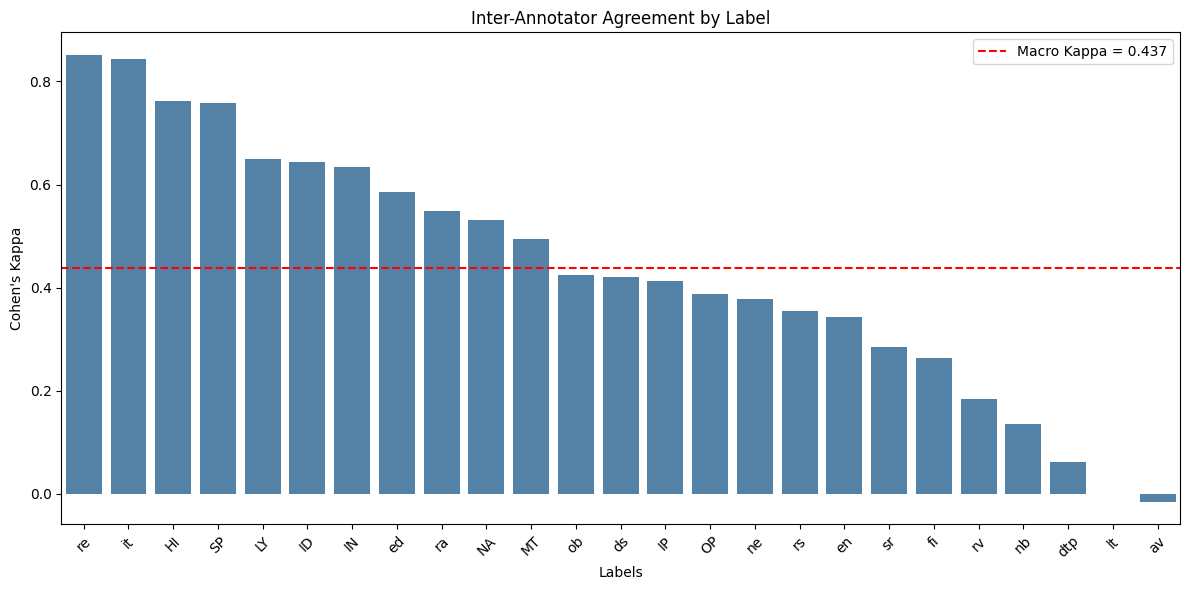

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=kappa_df,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue"
)

plt.axhline(
    macro_kappa,
    color="red",
    linestyle="--",
    label=f"Macro Kappa = {macro_kappa:.3f}"
)

plt.xticks(rotation=45)
plt.ylabel("Cohen's Kappa")
plt.xlabel("Labels")
plt.title("Inter-Annotator Agreement by Label")
plt.legend()
plt.tight_layout()
plt.show()

## Main Vs sub

In [31]:
main_labels = list(labels_structure.keys())

sub_labels = [
    sub
    for subs in labels_structure.values()
    for sub in subs
]

print("Main labels:", main_labels)
print("Sub labels:", sub_labels)

Main labels: ['MT', 'LY', 'SP', 'ID', 'NA', 'HI', 'IN', 'OP', 'IP']
Sub labels: ['it', 'ne', 'sr', 'nb', 're', 'en', 'ra', 'dtp', 'fi', 'lt', 'rv', 'ob', 'rs', 'av', 'ds', 'ed']


In [32]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd
import numpy as np


def calculate_kappa(df, labels):

    results = []

    def extract_labels(value):
        if pd.isna(value) or not str(value).strip():
            return set()

        return set(str(value).split())

    for label in labels:

        ann_1 = df["label_ann_1"].apply(
            lambda x: int(label in extract_labels(x))
        )

        ann_2 = df["label_ann_2"].apply(
            lambda x: int(label in extract_labels(x))
        )

        kappa = cohen_kappa_score(ann_1, ann_2)

        agreement = (ann_1 == ann_2).mean()

        results.append({
            "Label": label,
            "Ann_1_count": ann_1.sum(),
            "Ann_2_count": ann_2.sum(),
            "Agreement": agreement,
            "Cohen_Kappa": kappa
        })

    results_df = pd.DataFrame(results)

    return results_df

In [33]:
main_kappa = calculate_kappa(
    consolidated,
    main_labels
)

display(main_kappa.round(3))

,Label,Ann_1_count,Ann_2_count,Agreement,Cohen_Kappa
0,MT,20,7,0.938,0.494
1,LY,16,8,0.962,0.649
2,SP,37,26,0.938,0.759
3,ID,29,18,0.929,0.643
4,NA,59,36,0.833,0.532
5,HI,37,40,0.929,0.762
6,IN,90,77,0.824,0.634
7,OP,42,28,0.829,0.388
8,IP,38,42,0.819,0.414


In [34]:
sub_kappa = calculate_kappa(
    consolidated,
    sub_labels
)

display(sub_kappa.round(3))

,Label,Ann_1_count,Ann_2_count,Agreement,Cohen_Kappa
0,it,19,16,0.976,0.844
1,ne,21,24,0.881,0.378
2,sr,22,4,0.914,0.285
3,nb,13,1,0.943,0.135
4,re,20,17,0.976,0.852
5,en,18,4,0.933,0.343
6,ra,19,12,0.938,0.549
7,dtp,26,15,0.833,0.061
8,fi,17,4,0.929,0.263
9,lt,18,0,0.914,0.000


In [35]:
print(
    "Main labels macro Kappa:",
    round(main_kappa["Cohen_Kappa"].mean(), 3)
)

print(
    "Sub labels macro Kappa:",
    round(sub_kappa["Cohen_Kappa"].mean(), 3)
)

Main labels macro Kappa: 0.586
Sub labels macro Kappa: 0.354


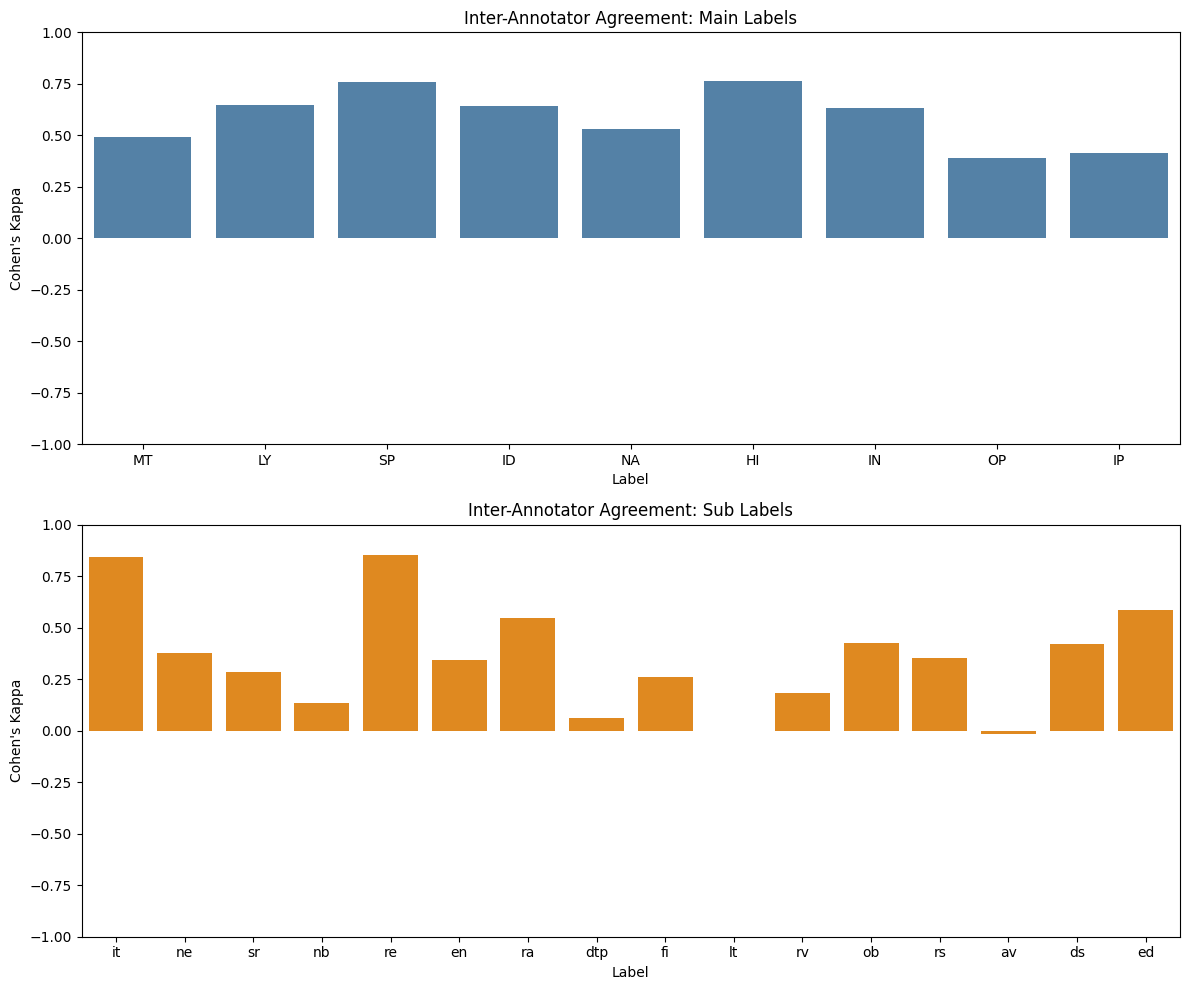

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Main labels
sns.barplot(
    data=main_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Inter-Annotator Agreement: Main Labels")
axes[0].set_ylim(-1, 1)
axes[0].set_ylabel("Cohen's Kappa")

# Sub labels
sns.barplot(
    data=sub_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Inter-Annotator Agreement: Sub Labels")
axes[1].set_ylim(-1, 1)
axes[1].set_ylabel("Cohen's Kappa")

plt.tight_layout()
plt.show()


# Fixed size plot

In [38]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [39]:
# ==========================================
# PLOTTING AND SAVING SETTINGS
# ==========================================

FIG_SIZE = (12, 7)
FIG_DPI = 300

OUTPUT_DIR = "plots"

plt.rcParams.update({
    "figure.figsize": FIG_SIZE,
    "figure.dpi": FIG_DPI,
    "savefig.dpi": FIG_DPI,
    "font.family": "Arial",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
})

In [40]:
def save_plot(fig, filename, output_dir=OUTPUT_DIR):

    os.makedirs(output_dir, exist_ok=True)

    # Save PNG
    png_path = os.path.join(output_dir, f"{filename}.png")

    fig.savefig(
        png_path,
        dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white",
        format="png"
    )

    # Save PDF
    pdf_path = os.path.join(output_dir, f"{filename}.pdf")

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
        format="pdf"
    )

    print(f"PNG saved: {png_path}")
    print(f"PDF saved: {pdf_path}")

PNG saved: plots\iaa_by_label.png
PDF saved: plots\iaa_by_label.pdf


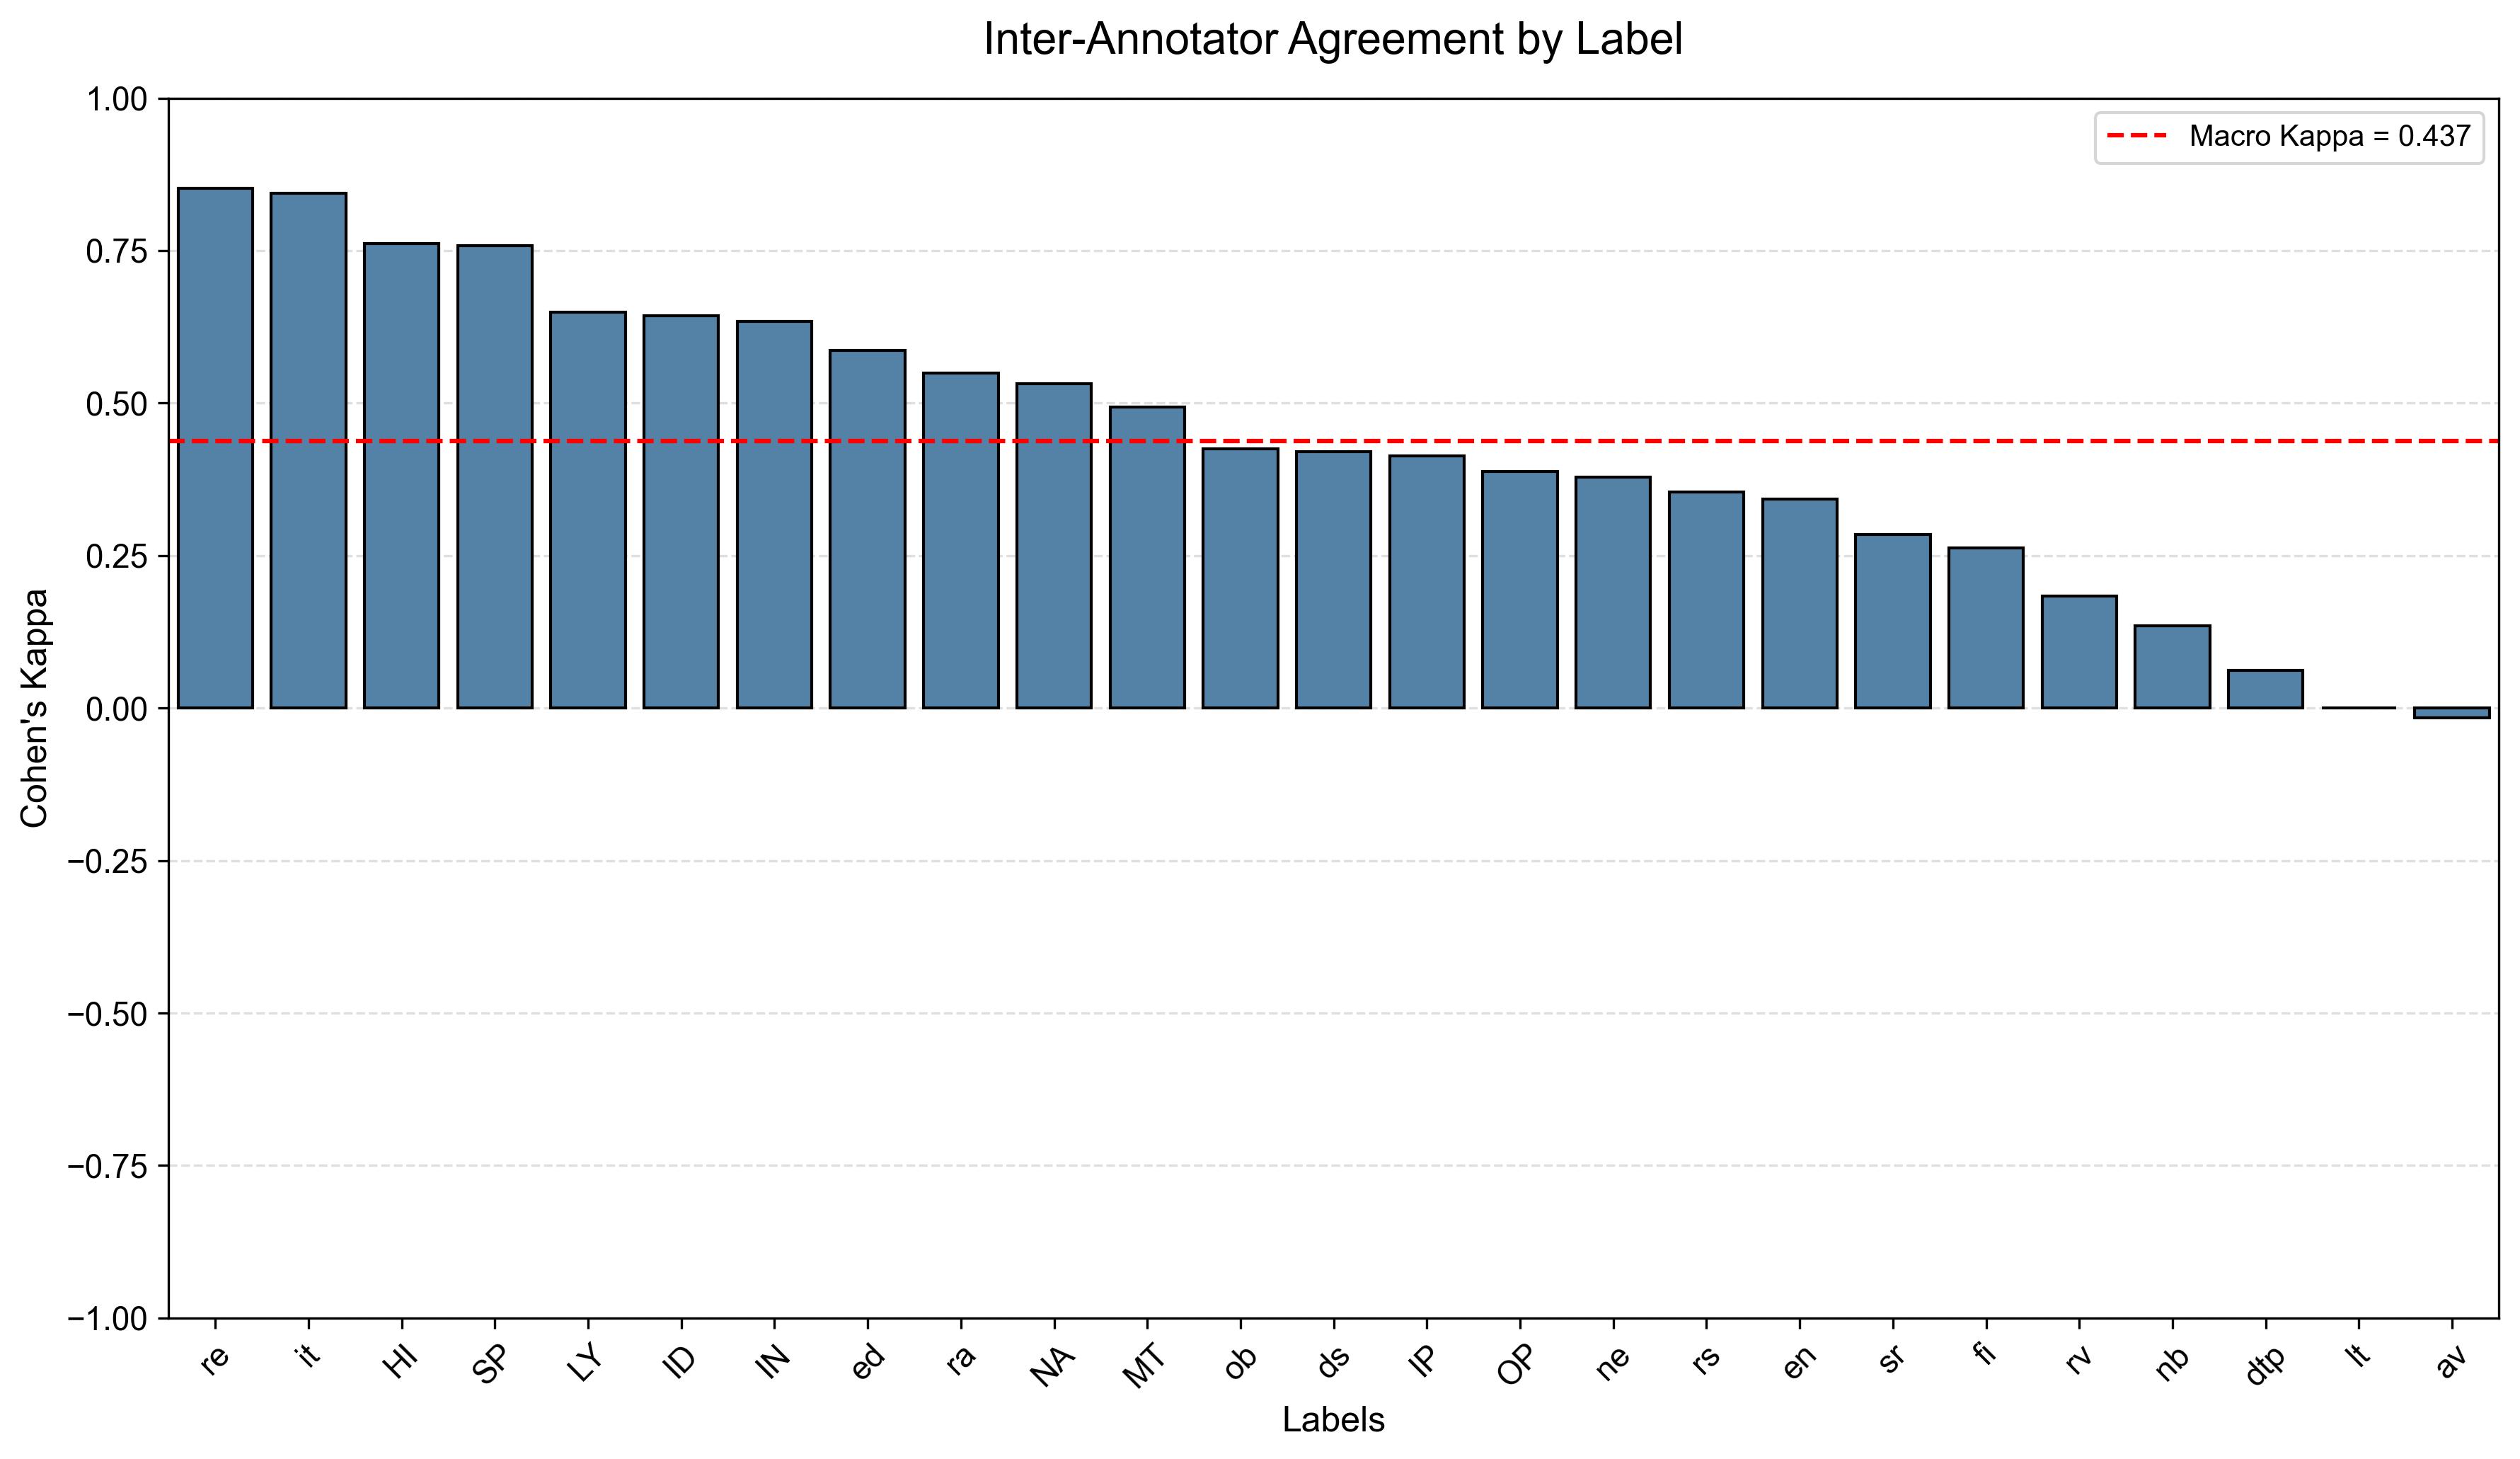

In [41]:
# ==========================================
# IAA: KAPPA BY LABEL
# ==========================================

fig, ax = plt.subplots(figsize=FIG_SIZE)

sns.barplot(
    data=kappa_df,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue",
    ax=ax,
    edgecolor="black"
)

# Macro-average line
ax.axhline(
    macro_kappa,
    color="red",
    linestyle="--",
    label=f"Macro Kappa = {macro_kappa:.3f}"
)

# Titles and labels
ax.set_title(
    "Inter-Annotator Agreement by Label",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Labels")
ax.set_ylabel("Cohen's Kappa")

# Formatting
ax.set_ylim(-1, 1)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.legend()

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()

# Save
save_plot(fig, "iaa_by_label")

# Display
plt.show()
plt.close(fig)

PNG saved: plots\iaa_by_label.png
PDF saved: plots\iaa_by_label.pdf


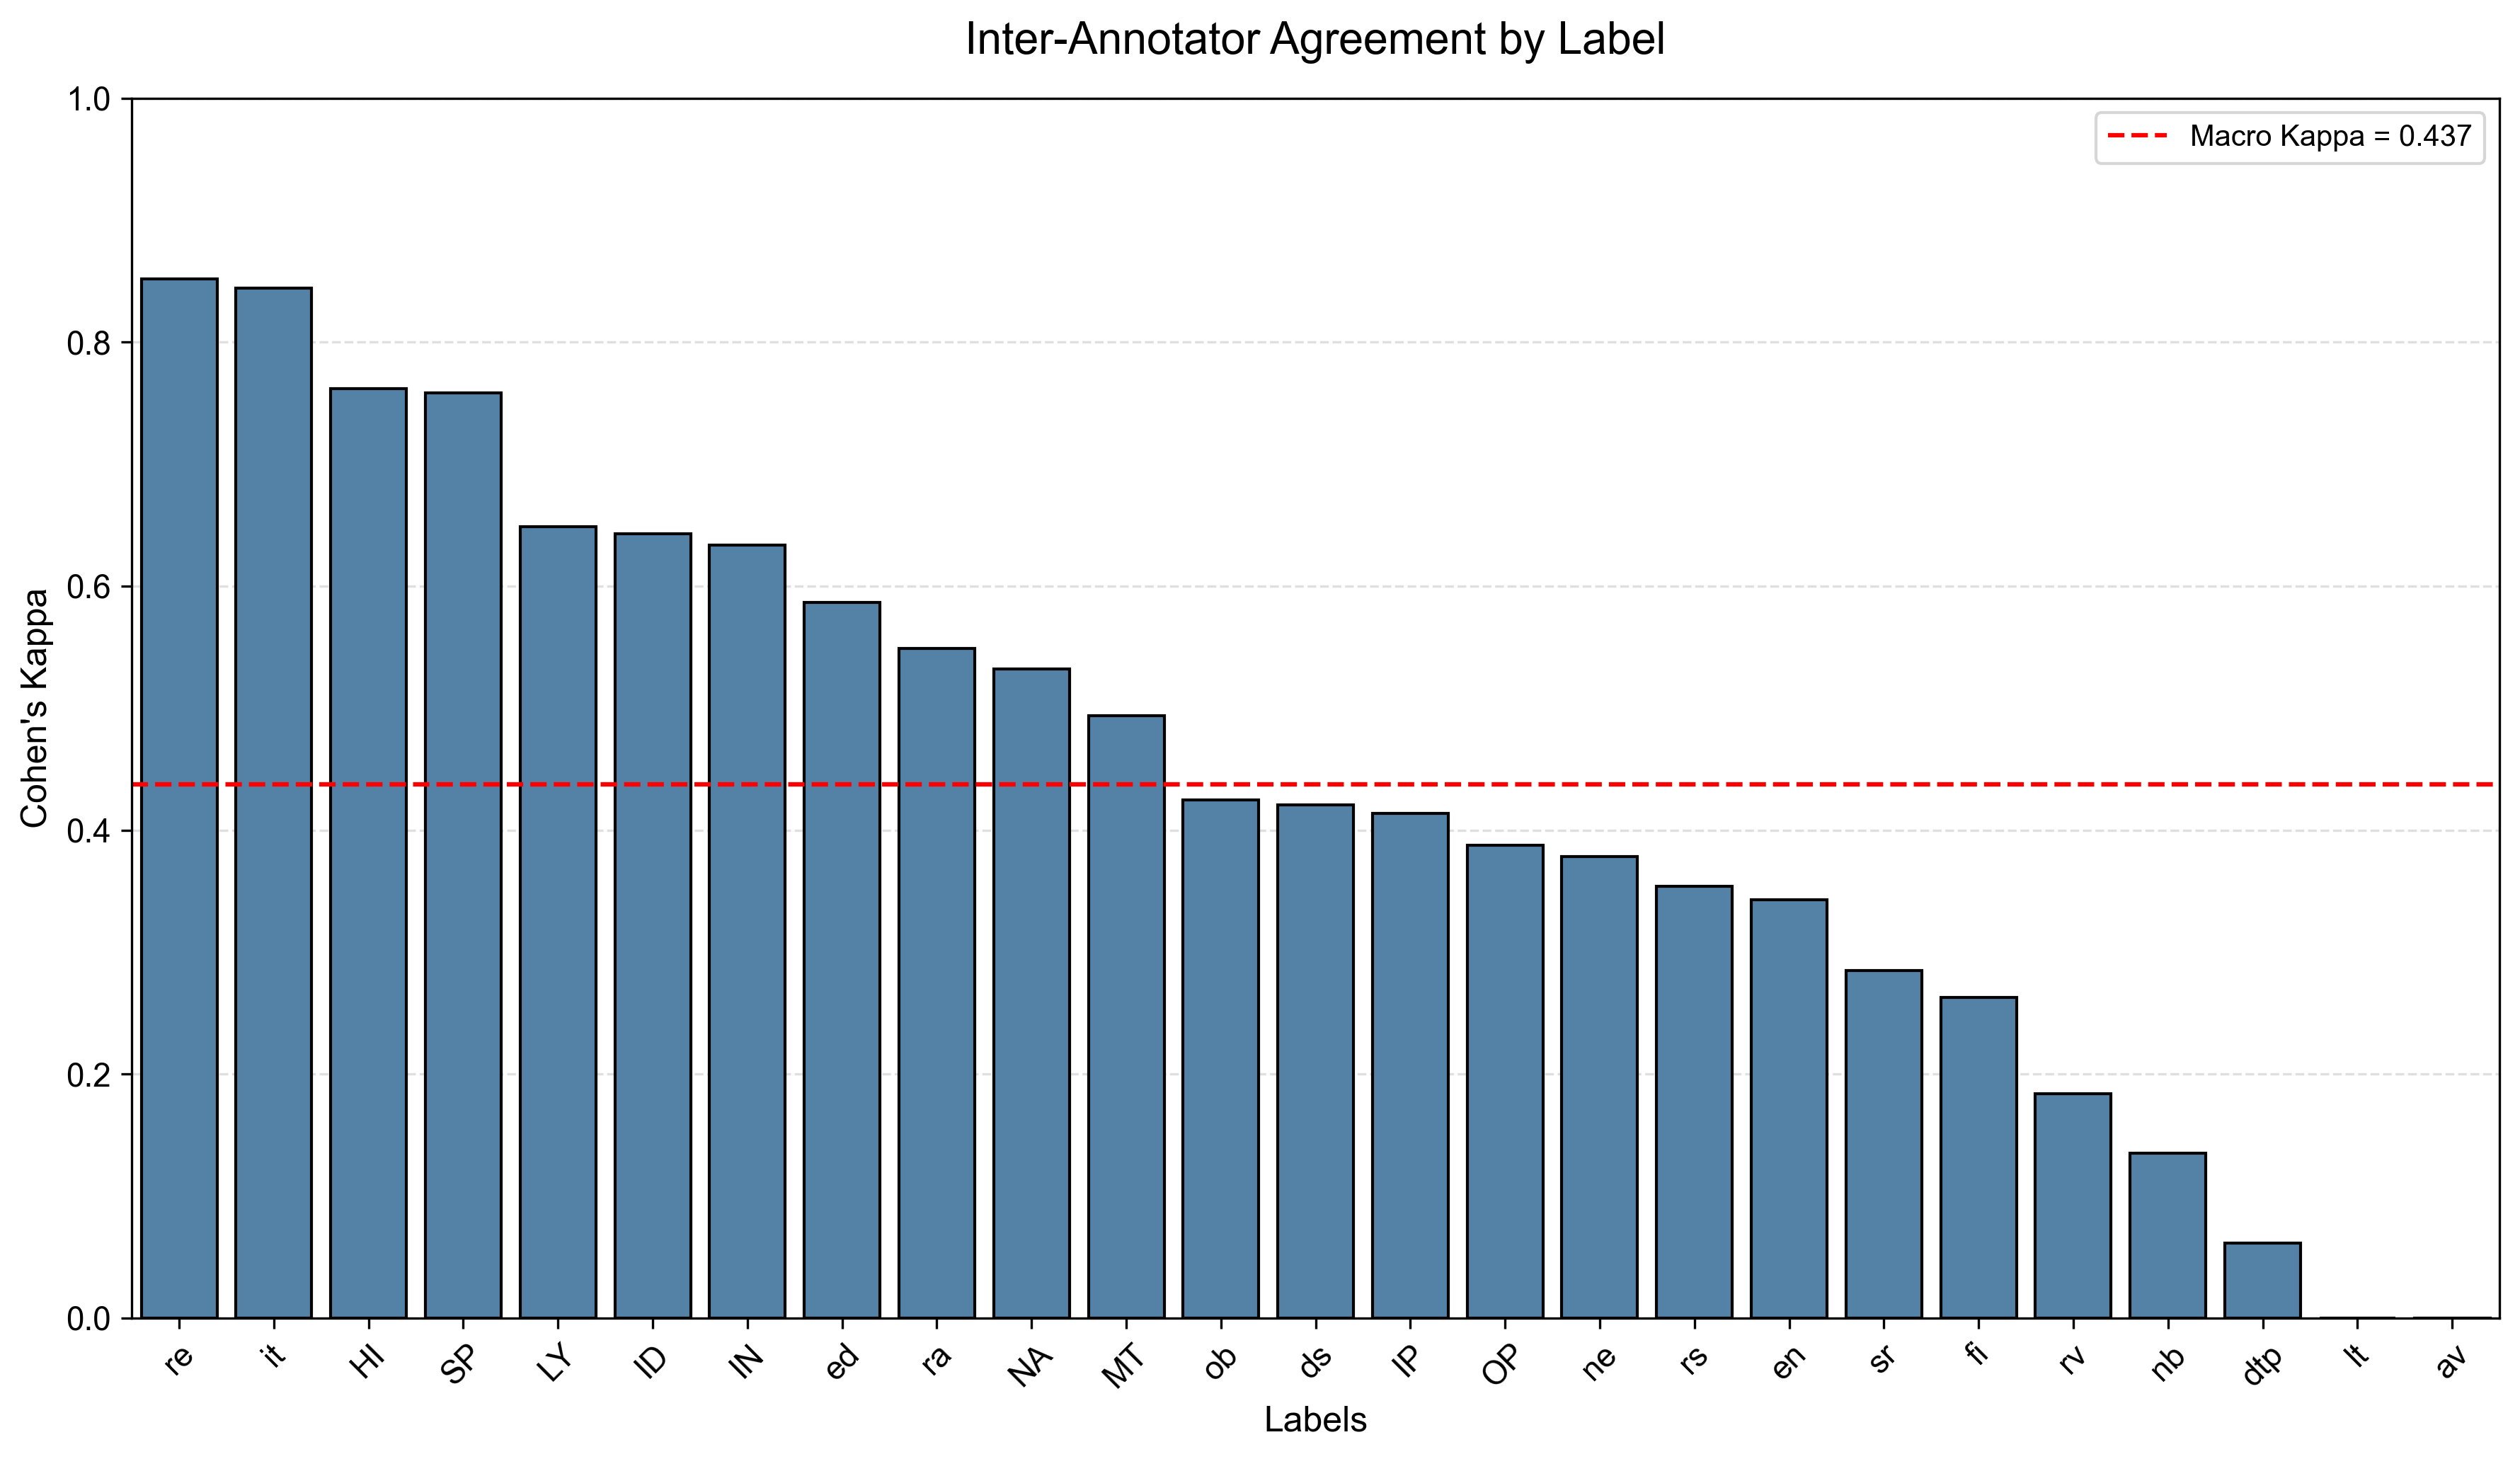

In [43]:
# ==========================================
# IAA: KAPPA BY LABEL
# ==========================================

fig, ax = plt.subplots(figsize=FIG_SIZE)

sns.barplot(
    data=kappa_df,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue",
    ax=ax,
    edgecolor="black"
)

# Macro-average line
ax.axhline(
    macro_kappa,
    color="red",
    linestyle="--",
    label=f"Macro Kappa = {macro_kappa:.3f}"
)

# Titles and labels
ax.set_title(
    "Inter-Annotator Agreement by Label",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Labels")
ax.set_ylabel("Cohen's Kappa")

# Formatting
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.legend()

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()

# Save
save_plot(fig, "iaa_by_label")

# Display
plt.show()
plt.close(fig)

PNG saved: plots\iaa_main_vs_sub.png
PDF saved: plots\iaa_main_vs_sub.pdf


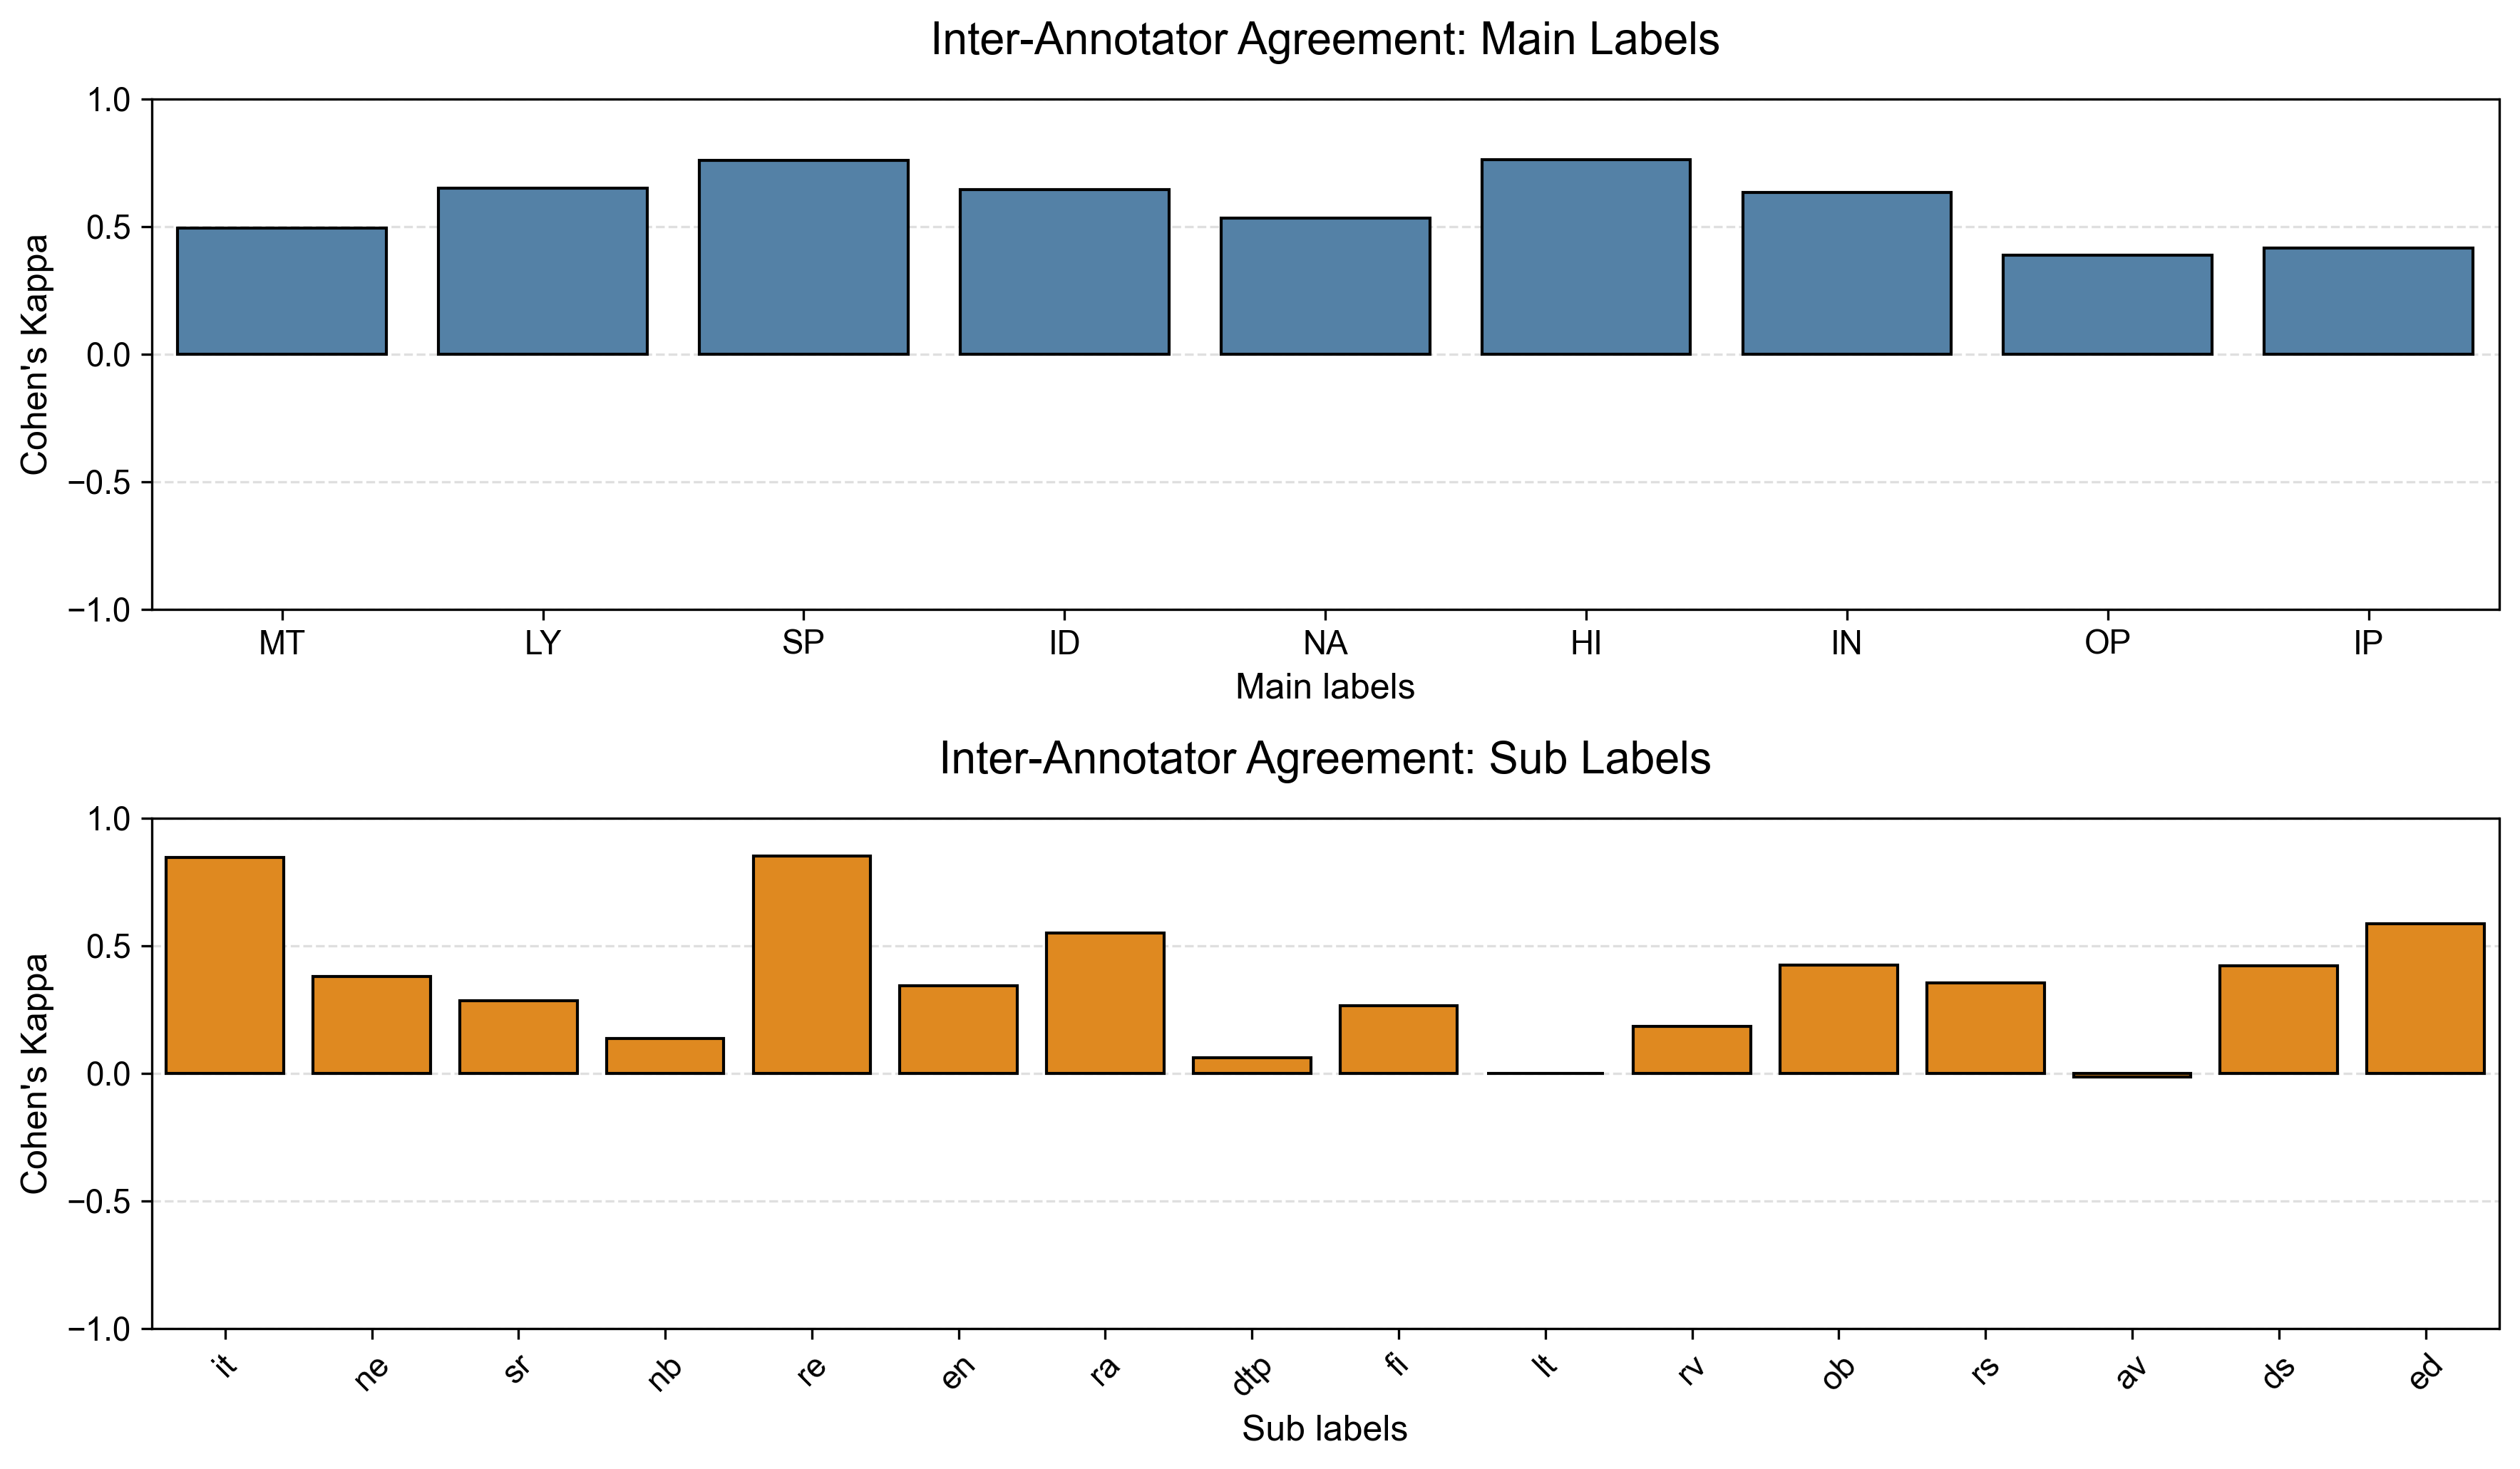

In [42]:
# ==========================================
# IAA: MAIN VS SUB LABELS
# ==========================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7)
)

# Main labels
sns.barplot(
    data=main_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue",
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title(
    "Inter-Annotator Agreement: Main Labels",
    fontsize=15,
    pad=15
)

axes[0].set_ylim(-1, 1)
axes[0].set_ylabel("Cohen's Kappa")
axes[0].set_xlabel("Main labels")

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

axes[0].set_axisbelow(True)


# Sub labels
sns.barplot(
    data=sub_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="darkorange",
    ax=axes[1],
    edgecolor="black"
)

axes[1].set_title(
    "Inter-Annotator Agreement: Sub Labels",
    fontsize=15,
    pad=15
)

axes[1].set_ylim(-1, 1)
axes[1].set_ylabel("Cohen's Kappa")
axes[1].set_xlabel("Sub labels")

axes[1].tick_params(
    axis="x",
    rotation=45
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

axes[1].set_axisbelow(True)


# Layout
fig.tight_layout()

# Save
save_plot(fig, "iaa_main_vs_sub")

# Display
plt.show()
plt.close(fig)

PNG saved: plots\iaa_main_vs_sub.png
PDF saved: plots\iaa_main_vs_sub.pdf


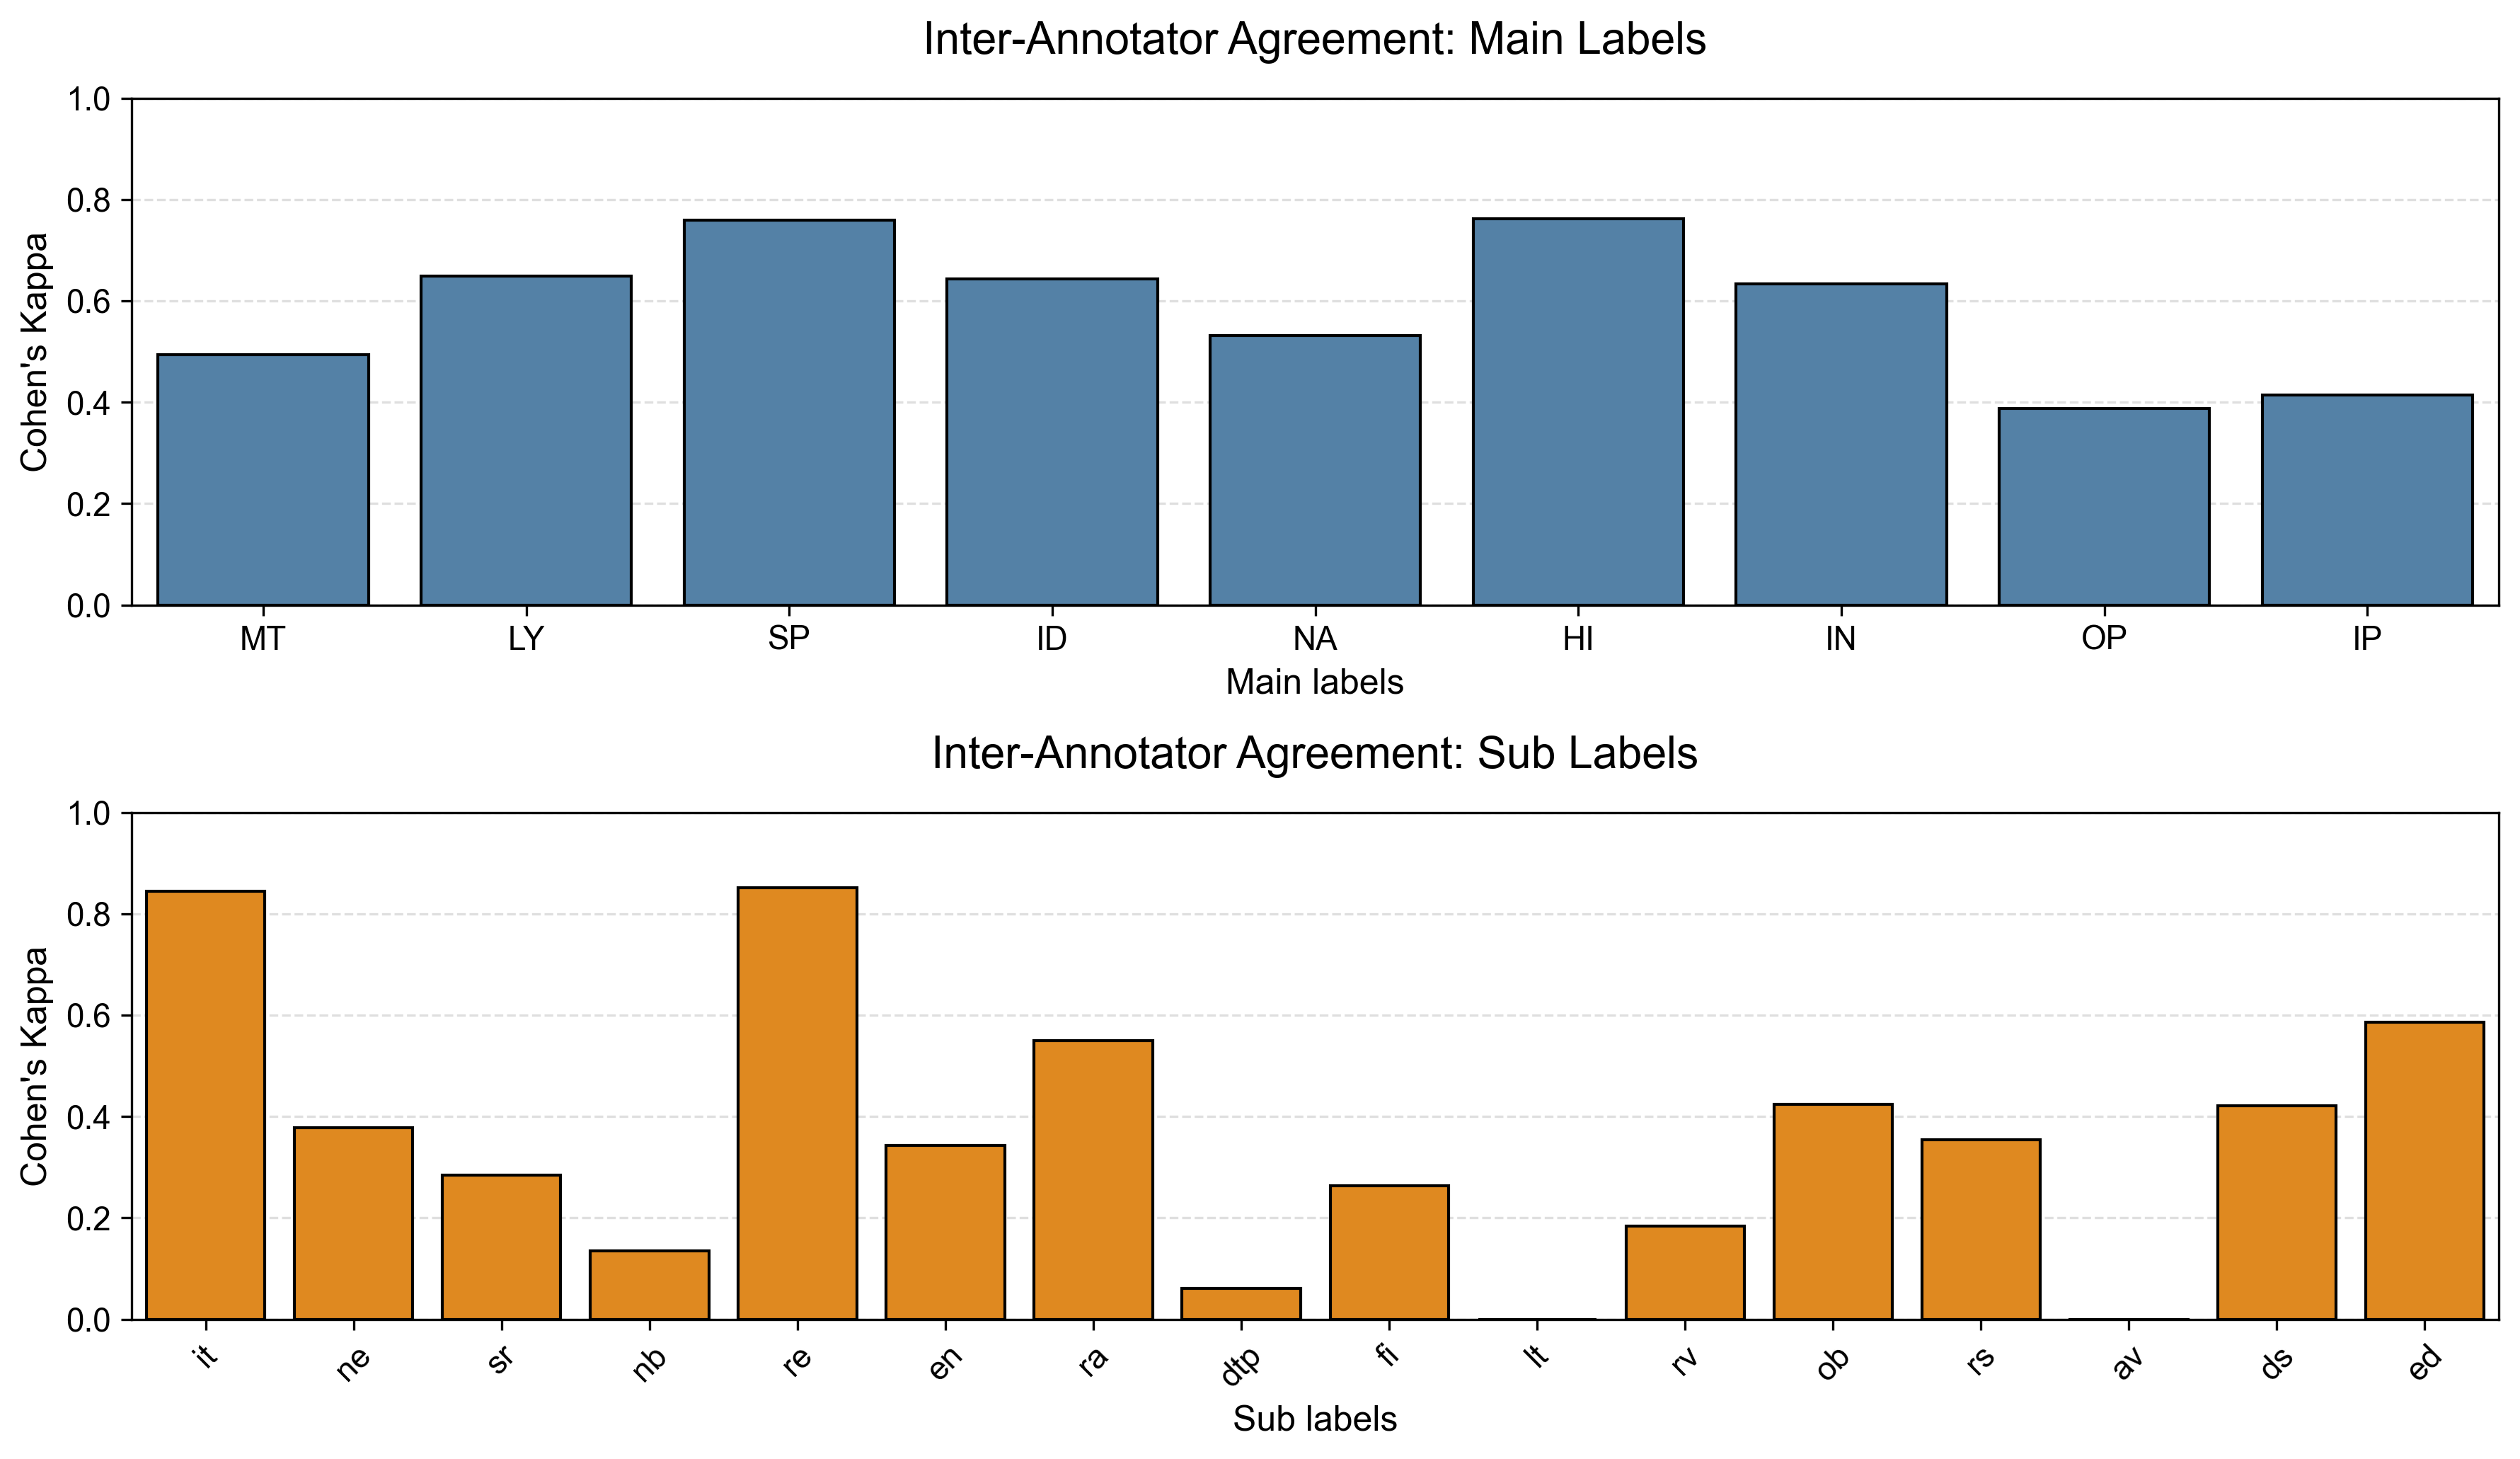

In [45]:
# ==========================================
# IAA: MAIN VS SUB LABELS
# ==========================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7)
)

# Main labels
sns.barplot(
    data=main_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="steelblue",
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title(
    "Inter-Annotator Agreement: Main Labels",
    fontsize=15,
    pad=15
)

axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Cohen's Kappa")
axes[0].set_xlabel("Main labels")

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

axes[0].set_axisbelow(True)


# Sub labels
sns.barplot(
    data=sub_kappa,
    x="Label",
    y="Cohen_Kappa",
    color="darkorange",
    ax=axes[1],
    edgecolor="black"
)

axes[1].set_title(
    "Inter-Annotator Agreement: Sub Labels",
    fontsize=15,
    pad=15
)

axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Cohen's Kappa")
axes[1].set_xlabel("Sub labels")

axes[1].tick_params(
    axis="x",
    rotation=45
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

axes[1].set_axisbelow(True)


# Layout
fig.tight_layout()

# Save
save_plot(fig, "iaa_main_vs_sub")

# Display
plt.show()
plt.close(fig)